# Fine-Tuning Qwen3 on HOMO-LUMO Data with Tinker: SFT + GRPO

This notebook walks you through fine-tuning a **Qwen3** model on the `Alan123/homo-lumo-grpo` dataset using the **Tinker API** from Thinking Machines Lab.

We'll cover two training stages:
1. **Supervised Fine-Tuning (SFT)** — teach the model the format and basic chemistry reasoning
2. **GRPO (Group Relative Policy Optimization)** — use reinforcement learning with a reward signal to improve accuracy

**What is Tinker?** Tinker is a training API that handles distributed GPU infrastructure so you can focus on data and algorithms. You write a simple Python loop on your CPU machine; Tinker runs the actual training on GPU clusters behind the scenes using LoRA.

**Prerequisites:**
- A Tinker API key (sign up at [tinker-console.thinkingmachines.ai](https://tinker-console.thinkingmachines.ai))
- A HuggingFace account with access to the dataset

**References:**
- [Tinker Docs](https://tinker-docs.thinkingmachines.ai/)
- [Tinker Cookbook](https://github.com/thinking-machines-lab/tinker-cookbook)
- [Loss Functions](https://tinker-docs.thinkingmachines.ai/losses)

## 1. Installation & Setup

In [ ]:
# Install Tinker SDK and dependencies
%pip install -q tinker transformers torch datasets numpy

In [ ]:
# 安装/更新 widgets 插件
%pip install -q -U ipywidgets jupyterlab_widgets

# 如果你是在本地 VS Code 或 Jupyter Lab 运行，建议安装完后重启一下内核 (Restart Kernel)

In [ ]:
# (Optional) Install the Tinker Cookbook for higher-level abstractions
!pip install -q git+https://github.com/thinking-machines-lab/tinker-cookbook.git

In [2]:
import os
from getpass import getpass

# Set your Tinker API key
if "TINKER_API_KEY" not in os.environ:
    os.environ["TINKER_API_KEY"] = getpass("Enter your Tinker API key: ")

# (Optional) HuggingFace token if the dataset is private/gated
if "HF_TOKEN" not in os.environ:
    os.environ["HF_TOKEN"] = getpass("Enter your HuggingFace token (or press Enter to skip): ")

In [6]:
import tinker
from tinker import types
import numpy as np
import json
import time

# Verify connection to Tinker
service_client = tinker.ServiceClient()
capabilities = service_client.get_server_capabilities()
print("Connected to Tinker! Available models:")
for m in capabilities.supported_models:
    if "Qwen3" in m.model_name:
        print(f"  - {m.model_name}")

Connected to Tinker! Available models:
  - Qwen/Qwen3-235B-A22B-Instruct-2507
  - Qwen/Qwen3-30B-A3B
  - Qwen/Qwen3-30B-A3B-Base
  - Qwen/Qwen3-30B-A3B-Instruct-2507
  - Qwen/Qwen3-32B
  - Qwen/Qwen3-4B-Instruct-2507
  - Qwen/Qwen3-8B
  - Qwen/Qwen3-8B-Base
  - Qwen/Qwen3-VL-235B-A22B-Instruct
  - Qwen/Qwen3-VL-30B-A3B-Instruct
  - Qwen/Qwen3.5-27B
  - Qwen/Qwen3.5-35B-A3B
  - Qwen/Qwen3.5-397B-A17B
  - Qwen/Qwen3.5-4B


## 2. Load and Explore the Dataset

We load the `Alan123/homo-lumo-grpo` dataset from HuggingFace. This dataset contains chemistry problems related to HOMO-LUMO gap predictions.

> **Note:** Adjust the column names below (`"prompt"`, `"answer"`, etc.) to match the actual schema of your dataset. Run the exploration cell first to see the column names.

In [4]:
#配置代理环境

import os
import socket

# 1. 设置你探测到的 IP 或 OrbStack 专用域名
# 如果 ip route 返回的是 192.168.1.5，就填 http://192.168.1.5:7897
proxy_host = "172.18.48.1" # 如果是纯原生 Linux
# proxy_host = "host.orb.internal" # 如果是 macOS OrbStack
# proxy_host = "172.xx.xx.xx" # 如果是 WSL2/Docker，填 ip route 出来的网关

proxy_url = f"http://{proxy_host}:7897"

# 2. 先做最简单的“端口探活”，不用发 HTTP 请求
def test_port(ip, port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.settimeout(2)
        return s.connect_ex((ip, port)) == 0

if test_port(proxy_host, 7897):
    print(f"✅ 成功发现代理服务：{proxy_url}")
    os.environ["http_proxy"] = proxy_url
    os.environ["https_proxy"] = proxy_url
    
    # 尝试加载数据
    from datasets import load_dataset
    try:
        # 这里建议先不传 token 试试，如果数据集是公开的
        dataset = load_dataset("Alan123/homo-lumo-grpo")
        print("🚀 数据集加载成功！")
    except Exception as e:
        print(f"❌ 代理通了但下载失败: {e}")
else:
    print(f"❌ 依然无法连接到 {proxy_host}:7897。请确认 Clash 的 'Allow LAN' 已开启。")

✅ 成功发现代理服务：http://172.18.48.1:7897


🚀 数据集加载成功！


In [7]:

# Load the dataset
dataset = load_dataset("Alan123/homo-lumo-grpo", token=os.environ.get("HF_TOKEN"))
print("Dataset splits:", list(dataset.keys()))
print("\nFirst split info:")
first_split = list(dataset.keys())[0]
print(f"  Split '{first_split}': {len(dataset[first_split])} examples")
print(f"  Columns: {dataset[first_split].column_names}")
print("\nFirst example:")
print(json.dumps(dataset[first_split][0:5], indent=2, default=str))

Using the latest cached version of the dataset since Alan123/homo-lumo-grpo couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'default' at /home/weekend/.cache/huggingface/datasets/Alan123___homo-lumo-grpo/default/0.0.0/354bfb2e17dd322e319a8dd127013def715a0713 (last modified on Wed Mar 25 10:54:02 2026).


Dataset splits: ['train']

First split info:
  Split 'train': 50420 examples
  Columns: ['input', 'output']

First example:
{
  "input": [
    "Given the intermediate molecule SMILES <SMILES>CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1</SMILES>, which is composed of fragments ['C(C)(C)C', 'c1ccc2occ()c2c1', 'C(=O)C', 'N', 'c1ccccc1F']. Propose a single replace, add or remove step on fragment level that makes the new molecule's HOMO value <HOMO>2.159</HOMO> higher, and LUMO value <LUMO>1.006</LUMO> higher.",
    "Given the intermediate molecule SMILES <SMILES>Cc1ccccc1C(=O)N1CCC2(CC1)C[C@H](c1ccccc1)C(=O)N2C</SMILES>, which is composed of fragments ['c1ccccc1C', 'C()=O', 'N1CCC2(CC1)C[C@H]()C(=O)N2C', 'c1ccccc1']. Propose a single replace, add or remove step on fragment level that makes the new molecule's HOMO value <HOMO>0.575</HOMO> higher, and LUMO value <LUMO>0.283</LUMO> lower.",
    "Given the intermediate molecule SMILES <SMILES>N#Cc1ccncc1NC[C@@H]1C[C@@]12CCc1ccccc12</SMILES>, which 

In [8]:
# ============================================================================
# IMPORTANT: Update these column names based on your dataset's actual schema!
# ============================================================================
# After running the cell above, check the column names and update accordingly.
#
# Common patterns for GRPO chemistry datasets:
#   - "prompt" or "question" or "smiles" or "input" -> the question/molecule
#   - "answer" or "target" or "homo_lumo_gap" or "label" -> the ground truth
#   - "messages" -> pre-formatted chat messages
#
# We provide TWO paths below:
#   Path A: Dataset has "prompt" and "answer" columns
#   Path B: Dataset has pre-formatted "messages" column
#
# Uncomment the path that matches your dataset.

# --- Path A: prompt + answer columns ---
PROMPT_COL = "input"       # <-- UPDATE to your prompt column name
ANSWER_COL = "output"       # <-- UPDATE to your answer column name
DATA_SPLIT = "train"        # <-- UPDATE if needed

# --- Path B: pre-formatted messages ---
# MESSAGES_COL = "messages"  # <-- Uncomment if your dataset uses messages format

raw_data = dataset[DATA_SPLIT]
# raw_data = raw_data_origin[:10000]
print(raw_data)
print(f"Loaded {len(raw_data)} training examples")

Dataset({
    features: ['input', 'output'],
    num_rows: 50420
})
Loaded 50420 training examples


## 3. Configure the Model and Renderer

We'll use **Qwen3-8B** (a good balance of cost and capability). For larger-scale experiments, you can switch to `Qwen/Qwen3-30B-A3B` (MoE, very cost-effective) or `Qwen/Qwen3-32B` (dense).

Tinker uses a **Renderer** to convert chat messages into token sequences with proper special tokens and loss weights.

In [9]:
# Choose your base model
# Options: "Qwen/Qwen3-8B", "Qwen/Qwen3-30B-A3B", "Qwen/Qwen3-32B", etc.
BASE_MODEL = "Qwen/Qwen3-30B-A3B"

# LoRA rank: higher = more capacity but costs more. 32 is a good default.
LORA_RANK = 32

print(f"Base model: {BASE_MODEL}")
print(f"LoRA rank: {LORA_RANK}")

Base model: Qwen/Qwen3-30B-A3B
LoRA rank: 32


In [10]:
# Set up the renderer for Qwen3 chat format
# The renderer handles special tokens (<|im_start|>, <|im_end|>, etc.)
# and produces proper loss masks for training.

from tinker_cookbook import renderers, tokenizer_utils

tokenizer = tokenizer_utils.get_tokenizer(BASE_MODEL)
renderer = renderers.get_renderer('qwen3', tokenizer)

print(f"Tokenizer vocab size: {tokenizer.vocab_size}")
print(f"Stop sequences: {renderer.get_stop_sequences()}")

Tokenizer vocab size: 151643
Stop sequences: [151645]


## 4. Data Preparation Helpers

We need functions to convert our dataset into the format Tinker expects:
- **For SFT:** `types.Datum` with `model_input` and `loss_fn_inputs` (weights and target_tokens)
- **For GRPO:** Chat messages that can be rendered into prompts for sampling

In [11]:
# System prompt for chemistry HOMO-LUMO tasks
SYSTEM_PROMPT = (
    "You are a helpful chemistry assistant. You need to modify the input molecule to match specific property contraints."
)


def make_messages(example):
    """
    Convert a raw dataset example into a list of chat messages.
    Update this function based on your dataset's column schema.
    """
    # --- Path A: prompt + answer columns ---
    prompt_text = example[PROMPT_COL]
    answer_text = str(example[ANSWER_COL])

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": prompt_text},
        {"role": "assistant", "content": f"{answer_text}"}
    ]
    return messages

    # --- Path B: pre-formatted messages ---
    # return example[MESSAGES_COL]


def make_prompt_messages(example):
    """
    Create the prompt-only messages (no assistant response) for RL sampling.
    """
    prompt_text = example[PROMPT_COL]
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": prompt_text},
    ]
    return messages


# Test with the first example
test_msgs = make_messages(raw_data[0])
print("Sample messages:")
for m in test_msgs:
    print(f"  [{m['role']}]: {m['content'][:100]}...")

Sample messages:
  [system]: You are a helpful chemistry assistant. You need to modify the input molecule to match specific prope...
  [user]: Given the intermediate molecule SMILES <SMILES>CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1</SMILES>, whi...
  [assistant]: Replace c1ccc2occ()c2c1 with N to form <SMILES>CC(C)(C)NC(=O)CNc1ccccc1F</SMILES>....


In [39]:
def prepare_sft_datum(example):
    messages = make_messages(example)
    model_input, weights = renderer.build_supervised_example(messages)

    input_tokens = model_input.to_ints()
    weights_list = weights.tolist() if hasattr(weights, 'tolist') else list(weights)

    target_tokens = input_tokens[1:] + [input_tokens[-1]]
    weights_shifted = weights_list[1:] + [0]

    return types.Datum(
        model_input=types.ModelInput.from_ints(tokens=input_tokens[:-1]),
        loss_fn_inputs=dict(
            weights=weights_shifted[:-1],
            target_tokens=target_tokens[:-1],
        ),
    )



# Test: prepare one datum and inspect
test_datum = prepare_sft_datum(raw_data[0])
n_tokens = len(test_datum.model_input.to_ints())

# Debug: check what type the weights actually are
weights_val = test_datum.loss_fn_inputs['weights']
print(f"Weights type: {type(weights_val)}")
if hasattr(weights_val, '__len__') and len(weights_val) > 0:
    print(f"First element type: {type(weights_val[0])}, value: {weights_val[0]}")

Weights type: <class 'tinker.TensorData'>


## 5. Stage 1: Supervised Fine-Tuning (SFT)

SFT teaches the model the basic format and chemistry knowledge. We use the `cross_entropy` loss function, which trains the model to predict the next token for the assistant's response.

**Tinker's training loop:**
1. Prepare a batch of `Datum` objects
2. Call `forward_backward()` to compute gradients
3. Call `optim_step()` to update the LoRA weights
4. Repeat

In [40]:
# ========================
# SFT Hyperparameters
# ========================
SFT_LEARNING_RATE = 1e-4
SFT_BATCH_SIZE = 4           # Number of examples per gradient step
SFT_NUM_STEPS =  50          # Total training steps (adjust based on dataset size)
SFT_EVAL_EVERY = 10          # Evaluate every N steps
SFT_GRAD_ACCUM_STEPS = 1     # Gradient accumulation steps

print(f"SFT config: lr={SFT_LEARNING_RATE}, batch={SFT_BATCH_SIZE}, steps={SFT_NUM_STEPS}")

SFT config: lr=0.0001, batch=4, steps=50


In [ ]:
# Create the training client for SFT
sft_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
sft_checkpoint_path = "tinker://ea2049e4-7da6-5b78-a25b-8b920be01ff3:train:1/weights/Subprocess-sft500-fourstep-xml.Qwen3-8B" # <-- Set this to your checkpoint path if resuming
sft_training_client.load_state(sft_checkpoint_path)

SFT Training client created (run ID visible in Tinker console)


In [18]:
# Prepare all SFT data
print("Preparing SFT training data...")
sft_data = []
for i, example in enumerate(raw_data):
    try:
        datum = prepare_sft_datum(example)
        sft_data.append(datum)
    except Exception as e:
        if i < 3:
            print(f"  Warning: skipping example {i}: {e}")

print(f"Prepared {len(sft_data)} SFT examples")

# Split into train/test
split_idx = int(0.9 * len(sft_data))
sft_train = sft_data[:split_idx]
sft_test = sft_data[split_idx:]
print(f"Train: {len(sft_train)}, Test: {len(sft_test)}")

Preparing SFT training data...
Prepared 50420 SFT examples
Train: 45378, Test: 5042


In [42]:
# ========================
# SFT Training Loop
# ========================
sft_metrics = []
rng = np.random.default_rng(42)

print("Starting SFT training...")
print(f"{'Step':>5} | {'Train Loss':>10} | {'Test Loss':>10} | {'Time (s)':>8}")
print("-" * 50)

for step in range(SFT_NUM_STEPS):
    t0 = time.time()

    # Sample a mini-batch
    batch_indices = rng.choice(len(sft_train), size=SFT_BATCH_SIZE, replace=False)
    batch = [sft_train[i] for i in batch_indices]

    # Forward-backward pass with cross-entropy loss
    fwdbwd_future = sft_training_client.forward_backward(batch, loss_fn="cross_entropy")

    # Optimizer step
    optim_future = sft_training_client.optim_step(
        types.AdamParams(learning_rate=SFT_LEARNING_RATE)
    )

    # Wait for results
    fwdbwd_result = fwdbwd_future.result()
    optim_result = optim_future.result()

    # Compute train loss
    logprobs = np.concatenate(
        [out['logprobs'].tolist() for out in fwdbwd_result.loss_fn_outputs]
    )
    weights = np.concatenate(
        [d.loss_fn_inputs['weights'].tolist() if hasattr(d.loss_fn_inputs['weights'], 'tolist')
         else d.loss_fn_inputs['weights']
         for d in batch]
    )
    weights_arr = np.array(weights, dtype=float)
    train_loss = -np.dot(logprobs, weights_arr) / max(weights_arr.sum(), 1)

    elapsed = time.time() - t0
    metrics_entry = {"step": step, "train_loss": float(train_loss), "time": elapsed}

    # Periodic evaluation on test set
    if step % SFT_EVAL_EVERY == 0 and len(sft_test) > 0:
        test_batch = sft_test[:min(SFT_BATCH_SIZE, len(sft_test))]
        test_fwdbwd = sft_training_client.forward_backward(test_batch, loss_fn="cross_entropy")
        # Note: we don't call optim_step for test — just forward pass
        test_result = test_fwdbwd.result()
        test_logprobs = np.concatenate(
            [out['logprobs'].tolist() for out in test_result.loss_fn_outputs]
        )
        test_weights = np.concatenate(
            [d.loss_fn_inputs['weights'].tolist() if hasattr(d.loss_fn_inputs['weights'], 'tolist')
             else d.loss_fn_inputs['weights']
             for d in test_batch]
        )
        test_weights_arr = np.array(test_weights, dtype=float)
        test_loss = -np.dot(test_logprobs, test_weights_arr) / max(test_weights_arr.sum(), 1)
        metrics_entry["test_loss"] = float(test_loss)
        print(f"{step:>5} | {train_loss:>10.4f} | {test_loss:>10.4f} | {elapsed:>8.1f}")
    else:
        print(f"{step:>5} | {train_loss:>10.4f} | {'—':>10} | {elapsed:>8.1f}")

    sft_metrics.append(metrics_entry)

print("\nSFT training complete!")

Starting SFT training...
 Step | Train Loss |  Test Loss | Time (s)
--------------------------------------------------
    0 |     1.8334 |     2.4196 |      4.2
    1 |     1.3554 |          — |      2.9
    2 |     1.6621 |          — |      3.0
    3 |     1.3709 |          — |      3.0
    4 |     1.0878 |          — |      3.8
    5 |     1.0168 |          — |      3.5
    6 |     0.6832 |          — |      2.7
    7 |     0.8593 |          — |      2.6
    8 |     0.7382 |          — |      2.9
    9 |     0.6211 |          — |      3.1
   10 |     0.6591 |     0.7799 |      2.8
   11 |     0.5274 |          — |      3.0
   12 |     0.4943 |          — |      3.3
   13 |     0.5844 |          — |      2.7
   14 |     0.6128 |          — |      2.8
   15 |     0.5084 |          — |      2.7
   16 |     0.7180 |          — |      3.0
   17 |     0.5656 |          — |      2.7
   18 |     0.4848 |          — |      2.7
   19 |     0.5399 |          — |      2.9
   20 |     0.3257 | 

In [12]:
# Save the SFT checkpoint
# This saves the LoRA weights + optimizer state so we can:
#   1. Sample from the SFT model
#   2. Continue training with GRPO

sft_save_result = sft_training_client.save_state(name="sft-final.weekend.Qwen30B_001").result()
sft_checkpoint_path = sft_save_result.path
print(f"SFT checkpoint saved at: {sft_checkpoint_path}")

# Also save a sampler-only checkpoint (lighter weight)
sft_sampling_client = sft_training_client.save_weights_and_get_sampling_client(
    name="sft-sampler.weekend.Qwen30B_001"
)
print("SFT sampling client ready")

NameError: name 'sft_training_client' is not defined

In [44]:
# Test the SFT model with a sample prediction
test_example = raw_data[0]
test_prompt_msgs = make_prompt_messages(test_example)
prompt_input = renderer.build_generation_prompt(test_prompt_msgs)
stop_seqs = renderer.get_stop_sequences()

sample_result = sft_sampling_client.sample(
    prompt=prompt_input,
    sampling_params=types.SamplingParams(
        max_tokens=512,
        temperature=0.7,
        stop=stop_seqs,
    ),
    num_samples=1,
).result()

response_text = tokenizer.decode(sample_result.sequences[0].tokens)
print("=" * 60)
print("PROMPT:", test_example[PROMPT_COL][:500])
print("=" * 60)
print("MODEL RESPONSE (SFT):")
print(response_text)
print("=" * 60)
print("GROUND TRUTH:", test_example[ANSWER_COL])

PROMPT: Given the intermediate molecule SMILES <SMILES>CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1</SMILES>, which is composed of fragments ['C(C)(C)C', 'c1ccc2occ()c2c1', 'C(=O)C', 'N', 'c1ccccc1F']. Propose a single replace, add or remove step on fragment level that makes the new molecule's HOMO value <HOMO>2.159</HOMO> higher, and LUMO value <LUMO>1.006</LUMO> higher.
MODEL RESPONSE (SFT):
Replace c1ccc2occ()c2c1 with c1ccc2c(c1)N(C)Cc1ccc(=O)[nH]c12 to form <SMILES>CC(C)(C)c1ccc2c(c1)N(C)Cc1ccc(=O)[nH]c12</SMILES>.<|im_end|>
GROUND TRUTH: Replace c1ccc2occ()c2c1 with N to form <SMILES>CC(C)(C)NC(=O)CNc1ccccc1F</SMILES>.


## 6. Plot SFT Training Curves

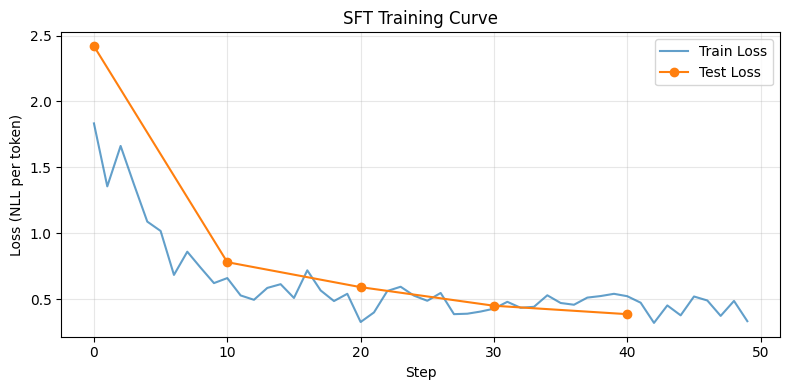

In [45]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot([m['step'] for m in sft_metrics], [m['train_loss'] for m in sft_metrics],
        label='Train Loss', alpha=0.7)
test_metrics = [m for m in sft_metrics if 'test_loss' in m]
if test_metrics:
    ax.plot([m['step'] for m in test_metrics], [m['test_loss'] for m in test_metrics],
            'o-', label='Test Loss')
ax.set_xlabel('Step')
ax.set_ylabel('Loss (NLL per token)')
ax.set_title('SFT Training Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## 7. Stage 2: GRPO (Reinforcement Learning)

Now we switch to **GRPO-style RL training** to improve the model's accuracy using a reward signal.

**How GRPO works with Tinker:**
1. For each prompt, **sample G completions** from the current model
2. **Score** each completion with a reward function
3. Compute **group-normalized advantages** (subtract mean, divide by std within each group)
4. Use the `ppo` (or `importance_sampling`) loss to update the policy

Tinker's built-in `ppo` loss handles the clipped surrogate objective. The GRPO-specific part (group normalization of advantages) is done on the client side.

In [ ]:
# ## Replace this demo with real reward functions
# import re


# def extract_boxed_answer(text):
#     """
#     Extract the answer from \\boxed{...} format.
#     Returns None if no boxed answer is found.
#     """
#     # Match \boxed{...} allowing nested braces
#     matches = re.findall(r'\\boxed\{([^{}]*)\}', text)
#     if matches:
#         return matches[-1].strip()  # Take the last boxed answer
#     return None


# def compute_reward(completion_text, ground_truth):
#     """
#     Reward function for HOMO-LUMO predictions.

#     Returns a reward in [0, 1]:
#     - 1.0 if the predicted value is within tolerance of ground truth
#     - Partial credit based on relative error
#     - Small penalty for wrong format

#     Customize the tolerance and scoring based on your task!
#     """
#     extracted = extract_boxed_answer(completion_text)
#     # 2. 如果没有 boxed，尝试从全文提取第一个数字串（宽松模式）
#     if extracted is None:
#         # 这个正则会找整数或小数，例如 2.159 或 -1.0
#         maybe_numbers = re.findall(r"[-+]?\d*\.\d+|\d+", completion_text)
#         if maybe_numbers:
#             extracted = maybe_numbers[0] # 取到的第一个数字

#     # 3. 此时不再设置负分惩罚，给个基础分 0
#     format_reward = 0
#     # Format reward: small bonus for using \boxed{}
#     # format_reward = 0.1 if extracted is not None else -0.1
#     # format_reward = 

#     # if extracted is None:
#         # return format_reward

#     try:
#         pred = float(extracted)
#         true = float(ground_truth)

#         # Compute relative error
#         if abs(true) < 1e-8:
#             # For near-zero ground truth, use absolute error
#             error = abs(pred - true)
#             accuracy_reward = max(0, 1.0 - error)
#         else:
#             rel_error = abs(pred - true) / abs(true)
#             # Reward: 1.0 for exact, decays with error
#             accuracy_reward = max(0, 1.0 - rel_error)

#         return accuracy_reward

#     except (ValueError, TypeError, IndexError):
#         # Can't parse as number
#         return format_reward


# # Test the reward function
# print("Reward tests:")
# print(f"  Exact match:     {compute_reward('The answer is \\boxed{3.45}', '3.45')}")
# print(f"  Close:           {compute_reward('\\boxed{3.50}', '3.45')}")
# print(f"  Wrong:           {compute_reward('\\boxed{10.0}', '3.45')}")
# print(f"  No boxed answer: {compute_reward('I think it is 3.45', '3.45')}")

In [ ]:
%pip install rdkit

In [14]:
import re
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import QED
from rdkit.Chem import Descriptors
from rdkit.Chem import Crippen
from rdkit.Chem import rdFingerprintGenerator
from rdkit import RDLogger
import joblib
RDLogger.DisableLog("rdApp.*")

def extract_smiles(text):
    """
    专门从文本中提取 <SMILES> 标签内的内容
    """
    if text is None:
        return None
    match = re.search(r"<SMILES>(.*?)</SMILES>", text)
    if match:
        return match.group(1).strip()
    return None

def compute_similarity_reward(mol_pred, mol_target):
    """计算预测分子与目标分子之间的 Tanimoto 相似度"""
    if mol_pred is None or mol_target is None:
        return 0.0
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp_pred = gen.GetFingerprint(mol_pred)
    fp_target = gen.GetFingerprint(mol_target)
    return DataStructs.TanimotoSimilarity(fp_pred, fp_target)

def _clip01(x):
    return max(0.0, min(1.0, float(x)))

def _extract_signed_delta(prompt_text, prop_tag):
    """
    从 prompt 中提取类似: <HOMO>2.159</HOMO> higher / lower 的目标改变量。
    返回有符号 delta：higher 为正，lower 为负。
    """
    if not prompt_text:
        return None
    pattern_after = rf"<{prop_tag}>\s*([-+]?\d*\.?\d+)\s*</{prop_tag}>\s*(higher|lower)"
    m = re.search(pattern_after, prompt_text, flags=re.IGNORECASE)
    if not m:
        pattern_before = rf"(higher|lower)\s*.*?<{prop_tag}>\s*([-+]?\d*\.?\d+)\s*</{prop_tag}>"
        m2 = re.search(pattern_before, prompt_text, flags=re.IGNORECASE)
        if not m2:
            return None
        direction = m2.group(1).lower()
        value = float(m2.group(2))
    else:
        value = float(m.group(1))
        direction = m.group(2).lower()

    return value if direction == "higher" else -value

def _predict_homo_lumo_proxy(mol):
    """
    轻量 surrogate: 用 RDKit 描述符构造 HOMO/LUMO proxy。
    注意这是代理信号，不是量化计算值。
    """
    if mol is None:
        return None, None

    logp = Crippen.MolLogP(mol)
    tpsa = Descriptors.TPSA(mol)
    hacc = Descriptors.NumHAcceptors(mol)
    valence_e = Descriptors.NumValenceElectrons(mol)
    frac_sp3 = Descriptors.FractionCSP3(mol)

    # Heuristic proxies (stable for ranking/relative shaping)
    homo_proxy = 0.20 * logp + 0.015 * valence_e - 0.10 * (tpsa / 100.0) + 0.10 * (frac_sp3 - 0.5)
    lumo_proxy = -0.12 * logp + 0.15 * (tpsa / 100.0) + 0.06 * hacc

    # homo_pred = joblib.load("homo_ml_model.pkl").predict(features)[0]
    # lumo_pred = joblib.load("lumo_ml_model.pkl").predict(features)[0]

    return float(homo_proxy), float(lumo_proxy)

def _property_match_score(delta_pred, delta_target):
    """
    将“预测改变量”和“目标改变量”匹配为 0-1 分数。
    """
    if delta_pred is None or delta_target is None:
        return None
    scale = 0.2 + 0.5 * abs(delta_target)
    return float(_clip01((2.718281828) ** (-abs(delta_pred - delta_target) / max(scale, 1e-6))))

def compute_reward(completion_text, prompt_text, ground_truth):
    """
    目标驱动 reward: HOMO/LUMO 目标匹配为主，结构奖励为辅。
    - completion_text: 模型输出
    - prompt_text: 包含 HOMO/LUMO higher/lower 目标的输入文本
    - ground_truth: 包含目标分子的输出文本（用于相似度兜底）
    """
    predicted_smiles = extract_smiles(completion_text)
    target_smiles = extract_smiles(ground_truth) or (ground_truth or "").strip()

    # 基础格式/合法性奖励
    reward_base = 0.0
    if predicted_smiles:
        reward_base += 0.05
    else:
        return 0.0

    mol_pred = Chem.MolFromSmiles(predicted_smiles)
    if mol_pred is None:
        return reward_base
    reward_base += 0.2

    # 解析目标改变量（来自 prompt）
    homo_target_delta = _extract_signed_delta(prompt_text, "HOMO")
    lumo_target_delta = _extract_signed_delta(prompt_text, "LUMO")

    # 计算 pred/base 的 proxy 改变量
    base_smiles = extract_smiles(prompt_text)

    # 现在不使用线性预测
    # homo_pred, lumo_pred = _predict_homo_lumo_proxy(mol_pred)
    # homo_base, lumo_base = _predict_homo_lumo_proxy(mol_base)

    # 使用QDF预测
    homo_lumo_Reward = None
    if base_smiles and homo_target_delta is not None and lumo_target_delta is not None:
        model = globals().get("qdf_reward_model", None)
        if model is None and "init_qdf_reward_model" in globals():
            try:
                model = globals()["init_qdf_reward_model"]()
            except Exception:
                model = None

        if model is not None:
            try:
                smiles = [predicted_smiles, base_smiles]
                homo_lumo_Reward = model.get_reward(
                    smiles=smiles,
                    target_homo_delta=homo_target_delta,
                    target_lumo_delta=lumo_target_delta,
                )
            except Exception:
                homo_lumo_Reward = None

    # homo_delta_pred = (homo_pred - homo_base) if (homo_pred is not None and homo_base is not None) else None
    # lumo_delta_pred = (lumo_pred - lumo_base) if (lumo_pred is not None and lumo_base is not None) else None

    # homo_score = _property_match_score(homo_delta_pred, homo_target_delta)
    # lumo_score = _property_match_score(lumo_delta_pred, lumo_target_delta)

    # # 属性项为主：有一个就用一个，两个都有就平均
    # prop_scores = [s for s in [homo_score, lumo_score] if s is not None]
    # prop_score = sum(prop_scores) / len(prop_scores) if prop_scores else None

    # 结构项兜底（当属性项不可用时）
    mol_target = Chem.MolFromSmiles(target_smiles)
    sim_score = compute_similarity_reward(mol_pred, mol_target)
    qed_score = QED.qed(mol_pred)
    structure_score = (sim_score * qed_score) ** 0.5

    # if prop_score is None:
    #     final = reward_base + 0.75 * structure_score
    # else:
    #     final = reward_base + 0.75 * prop_score

    if homo_lumo_Reward is None:
        final = reward_base + 0.75 * structure_score
    else:
        final = reward_base + 0.75 * homo_lumo_Reward

    return float(_clip01(final))

In [1]:
# # 自己训练一个模型预测lumo

# import joblib
# import numpy as np
# from rdkit import Chem
# from rdkit.Chem import AllChem, Descriptors

# class MLMolecularRewardModel:
#     def __init__(self, target_homo_delta, target_lumo_delta, base_homo, base_lumo):
#         # 加载预训练好的 ML 权重
#         try:
#             self.homo_regressor = joblib.load("homo_ml_model.pkl")
#             self.lumo_regressor = joblib.load("lumo_ml_model.pkl")
#         except:
#             print("警告：未找到 ML 模型文件，请确保模型已训练并保存。")
        
#         self.target_homo_delta = target_homo_delta
#         self.target_lumo_delta = target_lumo_delta
#         self.base_homo = base_homo
#         self.base_lumo = base_lumo

#     def _extract_features(self, mol):
#         """必须与训练时的特征提取逻辑完全一致"""
#         fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=2048)
#         desc = [Descriptors.MolLogP(mol), Descriptors.MolWt(mol), Descriptors.NumValenceElectrons(mol)]
#         return np.array(list(fp) + desc).reshape(1, -1)

#     def predict_properties(self, smiles):
#         mol = Chem.MolFromSmiles(smiles)
#         if mol is None: return None, None
        
#         features = self._extract_features(mol)
#         homo_pred = self.homo_regressor.predict(features)[0]
#         lumo_pred = self.lumo_regressor.predict(features)[0]
#         return homo_pred, lumo_pred

#     def __call__(self, smiles_list, prompts=None):
#         rewards = []
#         for s in smiles_list:
#             # 1. 基础合法性检查 (学长论文中的 -10 惩罚)
#             mol = Chem.MolFromSmiles(s)
#             if mol is None:
#                 rewards.append(-10.0)
#                 continue
            
#             # 2. 预测绝对值
#             h_val, l_val = self.predict_properties(s)
            
#             # 3. 计算 Delta 改变量
#             delta_h = h_val - self.base_homo
#             delta_l = l_val - self.base_lumo
            
#             # 4. 计算 MAE 奖励 (遵循 1 - MAE 逻辑)
#             mae = abs(delta_h - self.target_homo_delta) + abs(delta_l - self.target_lumo_delta)
            
#             # 限制奖励范围，防止过大的负值干扰训练
#             reward = 1.0 - mae
#             rewards.append(max(reward, -10.0))
            
#         return rewards

In [ ]:
import os
import re
import inspect
import pickle
import importlib.util
from pathlib import Path

import torch
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem

# 假设你已经 git clone 了 QuantumDeepField_molecule 仓库
# 并将其路径加入了 sys.path
# sys.path.append('/path/to/QuantumDeepField_molecule')

QDF_ROOT = Path("/home/weekend/workspace/AI4Materials/QuantumDeepField_molecule")
QDF_TRAIN_DIR = QDF_ROOT / "train"
QDF_TRAIN_FILE = QDF_TRAIN_DIR / "train.py"

if not QDF_TRAIN_FILE.exists():
    raise FileNotFoundError(f"未找到 QDF train.py: {QDF_TRAIN_FILE}")

_spec = importlib.util.spec_from_file_location("qdf_train", str(QDF_TRAIN_FILE))
if _spec is None or _spec.loader is None:
    raise ImportError(f"无法从文件加载模块: {QDF_TRAIN_FILE}")

qdf_train = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(qdf_train)


def _parse_qdf_model_setting(model_path):
    """从 model--xxx--k1v1--k2v2... 文件名提取 QDF 结构配置。"""
    name = Path(model_path).name
    if not name.startswith("model--"):
        return None

    body = name[len("model--"):]
    parts = body.split("--")
    if len(parts) < 2:
        return None

    dataset_name = parts[0]
    cfg = {
        "dataset_name": dataset_name,
        "basis_set": "6-31G",
        "dim": 250,
        "layer_functional": 3,
        "hidden_HK": 250,
        "layer_HK": 3,
        "operation": "sum",
        "N_output": 2 if "homolumo" in dataset_name.lower() else 1,
    }

    for p in parts[1:]:
        if p.startswith("dim"):
            cfg["dim"] = int(p.replace("dim", ""))
        elif p.startswith("layer_functional"):
            cfg["layer_functional"] = int(p.replace("layer_functional", ""))
        elif p.startswith("hidden_HK"):
            cfg["hidden_HK"] = int(p.replace("hidden_HK", ""))
        elif p.startswith("layer_HK"):
            cfg["layer_HK"] = int(p.replace("layer_HK", ""))
        elif p in {"sum", "mean"}:
            cfg["operation"] = p
        elif re.match(r"^[A-Za-z0-9\-]+-[A-Za-z0-9\-]+$", p):
            cfg["basis_set"] = p
    return cfg


class QDFRewardModel:
    def __init__(self, homo_model_path, lumo_model_path, device='cuda', qdf_root=QDF_ROOT):
        self.device = torch.device(device if torch.cuda.is_available() else 'cpu')
        self.qdf_root = Path(qdf_root)
        self._warned_predict = False

        # 注意：你需要从 QDF 仓库导入具体的模型类，这里以抽象类名为例
        # from model import QuantumDeepField

        # 加载 HOMO 模型
        self.homo_model = self._load_model(homo_model_path)

        # 加载 LUMO 模型
        self.lumo_model = self._load_model(lumo_model_path)

    def _build_model_from_state_dict(self, ckpt_path, state_dict):
        cfg = _parse_qdf_model_setting(ckpt_path)
        if cfg is None:
            raise ValueError(
                f"无法从 checkpoint 文件名解析 QDF 配置: {ckpt_path}。"
                "请提供可直接 torch.load 后调用的整模型文件。"
            )

        orbital_path = self.qdf_root / "dataset" / cfg["dataset_name"] / f"orbitaldict_{cfg['basis_set']}.pickle"
        if not orbital_path.exists():
            raise FileNotFoundError(
                f"未找到 orbital 字典: {orbital_path}。"
                "若你使用的是 HOMO/LUMO checkpoint，请确认 dataset 预处理文件已存在。"
            )

        with open(orbital_path, "rb") as f:
            orbital_dict = pickle.load(f)

        N_orbitals = len(orbital_dict)
        model = qdf_train.QuantumDeepField(
            self.device,
            N_orbitals,
            cfg["dim"],
            cfg["layer_functional"],
            cfg["operation"],
            cfg["N_output"],
            cfg["hidden_HK"],
            cfg["layer_HK"],
        ).to(self.device)

        model.load_state_dict(state_dict, strict=False)
        model.eval()
        return model

    def _load_model(self, model_path):
        model_path = Path(model_path)
        if not model_path.exists():
            raise FileNotFoundError(f"QDF 模型文件不存在: {model_path}")

        obj = torch.load(model_path, map_location=self.device)

        if isinstance(obj, torch.nn.Module):
            model = obj.to(self.device)
            model.eval()
            return model

        if isinstance(obj, dict):
            if "state_dict" in obj and isinstance(obj["state_dict"], dict):
                state_dict = obj["state_dict"]
            else:
                state_dict = obj
            return self._build_model_from_state_dict(str(model_path), state_dict)

        raise TypeError(f"不支持的 checkpoint 格式: {type(obj)}")

    def _smiles_to_qdf_input(self, smiles):
        """将 SMILES 转换为 QDF 需要的原子序数和 3D 坐标"""
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None

        try:
            # 1. 必须加氢，能级受氢键和质子化影响极大
            mol = Chem.AddHs(mol)
            # 2. 生成 3D 构象 (使用 ETKDG 算法)
            params = AllChem.ETKDG()
            params.useRandomCoords = True
            if AllChem.EmbedMolecule(mol, params) == -1:
                return None

            # 3. 简单的力场优化
            AllChem.MMFFOptimizeMolecule(mol)

            # 4. 提取数据
            conf = mol.GetConformer()
            atomic_nums = torch.tensor([a.GetAtomicNum() for a in mol.GetAtoms()], dtype=torch.long).to(self.device)
            coords = torch.tensor(conf.GetPositions(), dtype=torch.float32).to(self.device)

            return atomic_nums, coords
        except Exception:
            return None

    def _predict_single_model(self, model, atomic_nums, coords):
        """兼容不同模型 forward 签名。"""
        with torch.no_grad():
            try:
                sig = inspect.signature(model.forward)
                n_params = len(sig.parameters)
            except (TypeError, ValueError):
                n_params = 0

            # 你原来的调用方式：model(atomic_nums, coords)
            if n_params == 2:
                out = model(atomic_nums, coords)
            # QDF 原生 train.QuantumDeepField 需要 data tuple，
            # 这里无法直接从 smiles 拼出完整输入，返回 None 走 reward fallback。
            else:
                if not self._warned_predict:
                    print("[QDFRewardModel] 当前 checkpoint 的 forward 不是 (atomic_nums, coords) 形式，已回退为结构奖励。")
                    self._warned_predict = True
                return None

            if isinstance(out, (tuple, list)):
                out = out[0]
            if torch.is_tensor(out):
                if out.numel() == 0:
                    return None
                out = out.reshape(-1)[0].item()
            return float(out)

    def predict(self, smiles):
        data = self._smiles_to_qdf_input(smiles)
        if data is None:
            return None, None

        atomic_nums, coords = data

        homo_raw = self._predict_single_model(self.homo_model, atomic_nums, coords)
        lumo_raw = self._predict_single_model(self.lumo_model, atomic_nums, coords)
        if homo_raw is None or lumo_raw is None:
            return None, None

        # 转换为 eV（按你原有逻辑保留）
        homo_ev = float(homo_raw) * 27.2114
        lumo_ev = float(lumo_raw) * 27.2114
        return homo_ev, lumo_ev

    def get_reward(self, smiles, target_homo_delta, target_lumo_delta):
        """
        计算奖励：基于预测的改变量与目标改变量的 MAE
        """
        h_pred, l_pred = self.predict(smiles[0])
        h_base, l_base = self.predict(smiles[1])

        if h_pred is None or l_pred is None or h_base is None or l_base is None:
            return None

        if target_homo_delta is None or target_lumo_delta is None:
            return None

        # 计算当前的改变量 (Delta)
        current_h_delta = h_pred - h_base
        current_l_delta = l_pred - l_base

        # 计算 MAE
        mae = abs(current_h_delta - target_homo_delta) + abs(current_l_delta - target_lumo_delta)

        
        return 1.0 - mae


# 你可以通过环境变量覆盖路径：QDF_HOMO_MODEL_PATH / QDF_LUMO_MODEL_PATH
DEFAULT_QDF_MODEL = QDF_ROOT / "output" / "model--QM9under14atoms_atomizationenergy_eV--6-31G--radius0.75--grid_interval0.3--dim250--layer_functional3--hidden_HK250--layer_HK3--sum--batch_size4--lr1e-4--lr_decay0.5--step_size200--iteration2000"
homo_model_path = os.environ.get("QDF_HOMO_MODEL_PATH", str(DEFAULT_QDF_MODEL))
lumo_model_path = os.environ.get("QDF_LUMO_MODEL_PATH", str(DEFAULT_QDF_MODEL))


qdf_reward_model = None


def init_qdf_reward_model():
    global qdf_reward_model
    if qdf_reward_model is None:
        qdf_reward_model = QDFRewardModel(homo_model_path, lumo_model_path, device='cuda')
    return qdf_reward_model

In [15]:
# ========================
# GRPO Hyperparameters
# ========================
GRPO_LEARNING_RATE = 3e-6    # Lower LR for RL (typical: 1e-6 to 1e-5)
GRPO_NUM_ITERATIONS = 10     # Number of RL iterations
GRPO_PROMPTS_PER_ITER = 4    # Prompts sampled per iteration
GRPO_SAMPLES_PER_PROMPT = 8  # Completions generated per prompt (the "G" in GRPO)
GRPO_MAX_TOKENS = 512        # Max tokens per completion
GRPO_TEMPERATURE = 0.5       # Sampling temperature

print(f"GRPO config:")
print(f"  LR: {GRPO_LEARNING_RATE}")
print(f"  Iterations: {GRPO_NUM_ITERATIONS}")
print(f"  Prompts/iter: {GRPO_PROMPTS_PER_ITER}")
print(f"  Samples/prompt: {GRPO_SAMPLES_PER_PROMPT}")
print(f"  Total completions/iter: {GRPO_PROMPTS_PER_ITER * GRPO_SAMPLES_PER_PROMPT}")

GRPO config:
  LR: 3e-06
  Iterations: 10
  Prompts/iter: 4
  Samples/prompt: 8
  Total completions/iter: 32


In [16]:
# Create a NEW training client for GRPO, starting from the SFT checkpoint
grpo_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)

# Load the SFT weights as our starting point
grpo_training_client.load_state("tinker://eb393fba-89e6-5005-b2f2-3df09d6142c3:train:3/weights/sft-final.weekend.Qwen30B_001")
print("Loaded SFT checkpoint into GRPO training client")

# Create initial sampling client
grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(
    name="grpo-init"
)
print("GRPO sampling client ready")

Loaded SFT checkpoint into GRPO training client
GRPO sampling client ready


In [17]:
def compute_group_advantages(rewards):
    """
    Compute GRPO-style group-normalized advantages.

    Given rewards for a group of completions from the same prompt,
    normalize by subtracting the group mean and dividing by group std.

    Args:
        rewards: list of float rewards for one prompt's completions

    Returns:
        list of float advantages
    """
    rewards = np.array(rewards, dtype=np.float64)
    mean = rewards.mean()
    std = rewards.std()
    if std < 1e-8:
        # All rewards the same — no signal
        return [0.0] * len(rewards)
    advantages = (rewards - mean) / std
    return advantages.tolist()

In [18]:
# ========================
# GRPO Training Loop
# ========================
grpo_metrics = []
rng = np.random.default_rng(123)
stop_seqs = renderer.get_stop_sequences()

print("Starting GRPO training...")
print(f"{'Iter':>4} | {'Mean Reward':>11} | {'Max Reward':>10} | {'Correct%':>8} | {'Time (s)':>8}")
print("-" * 60)

for iteration in range(GRPO_NUM_ITERATIONS):
    t0 = time.time()

    # 1. Sample a batch of prompts
    prompt_indices = rng.choice(len(raw_data), size=GRPO_PROMPTS_PER_ITER, replace=False)

    all_data = []        # Tinker Datum objects for training
    all_rewards = []     # For logging

    # Debug stats for data quality in this iteration
    target_total = 0
    target_valid = 0
    pred_total = 0
    pred_valid = 0

    for prompt_idx in prompt_indices:
        example = raw_data[int(prompt_idx)]
        ground_truth = str(example[ANSWER_COL])
        prompt_text = str(example[PROMPT_COL])

        # Track target parseability (prompt-level)
        target_total += 1
        target_smiles = extract_smiles(ground_truth) or ground_truth.strip()
        mol_target_debug = Chem.MolFromSmiles(target_smiles)
        if mol_target_debug is not None:
            target_valid += 1

        # Build the prompt
        prompt_msgs = make_prompt_messages(example)
        prompt_input = renderer.build_generation_prompt(prompt_msgs)

        # 2. Sample G completions from the current policy
        sample_result = grpo_sampling_client.sample(
            prompt=prompt_input,
            sampling_params=types.SamplingParams(
                max_tokens=GRPO_MAX_TOKENS,
                temperature=GRPO_TEMPERATURE,
                stop=stop_seqs,
            ),
            num_samples=GRPO_SAMPLES_PER_PROMPT,
        ).result()

        # 3. Score each completion
        group_rewards = []
        group_sequences = []

        for seq in sample_result.sequences:
            completion_text = tokenizer.decode(seq.tokens)

            # Track prediction parseability (completion-level)
            pred_total += 1
            pred_smiles = extract_smiles(completion_text)
            if pred_smiles:
                mol_pred_debug = Chem.MolFromSmiles(pred_smiles)
                if mol_pred_debug is not None:
                    pred_valid += 1

            reward = compute_reward(completion_text, prompt_text, ground_truth)
            group_rewards.append(reward)
            group_sequences.append(seq)

        # 4. Compute group-normalized advantages (the "GR" in GRPO)
        advantages = compute_group_advantages(group_rewards)

        # 5. Build training data for each completion
        prompt_tokens = prompt_input.to_ints()

        for seq, adv, sampling_lps in zip(
            group_sequences, advantages,
            [seq.logprobs for seq in group_sequences]
        ):
            if adv == 0.0:
                continue  # Skip if no learning signal

            completion_tokens = list(seq.tokens)
            full_tokens = prompt_tokens + completion_tokens

            # Target tokens are the completion tokens
            target_tokens = full_tokens[1:]

            # Sampling logprobs: 0 for prompt tokens, actual logprobs for completion
            n_prompt = len(prompt_tokens)
            n_completion = len(completion_tokens)

            # Build per-token advantages: 0 for prompt, advantage for completion
            per_token_advantages = [0.0] * (n_prompt - 1) + [adv] * n_completion

            # Sampling logprobs (from the sampling policy)
            # For prompt tokens, set to 0 (they won't contribute due to 0 advantage)
            if sampling_lps is not None:  # sampling_lps should not change dramatically, in ppo we clip the ratio of the logs
                sampling_logprobs_list = [0.0] * (n_prompt - 1) + list(sampling_lps)
            else:
                # sampling_logprobs_list = [0.0] * len(per_token_advantages)
                continue

            # Ensure all lists have the same length
            min_len = min(len(target_tokens), len(per_token_advantages), len(sampling_logprobs_list))

            datum = types.Datum(
                model_input=types.ModelInput.from_ints(tokens=full_tokens[:-1]),
                loss_fn_inputs=dict(
                    target_tokens=target_tokens[:min_len],
                    advantages=per_token_advantages[:min_len],
                    logprobs=sampling_logprobs_list[:min_len],
                ),
            )
            all_data.append(datum)

        all_rewards.extend(group_rewards)

    # 6. Training update with PPO loss
    if len(all_data) > 0:
        fwdbwd_future = grpo_training_client.forward_backward(
            all_data,
            loss_fn="ppo",  # PPO-clipped objective — handles importance weighting
            loss_fn_config={"clip_low_threshold": 0.9, "clip_high_threshold": 1.1}
        )
        optim_future = grpo_training_client.optim_step(
            types.AdamParams(learning_rate=GRPO_LEARNING_RATE)
        )
        fwdbwd_result = fwdbwd_future.result()
        optim_result = optim_future.result()

    # 7. Update the sampling client with new weights
    grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(
        name=f"grpo-iter-{iteration:04d}"
    )

    # Log metrics
    elapsed = time.time() - t0
    mean_reward = np.mean(all_rewards) if all_rewards else 0
    max_reward = np.max(all_rewards) if all_rewards else 0
    correct_frac = np.mean([r > 0.5 for r in all_rewards]) if all_rewards else 0
    target_valid_frac = (target_valid / target_total) if target_total else 0.0
    pred_valid_frac = (pred_valid / pred_total) if pred_total else 0.0

    metrics_entry = {
        "iteration": iteration,
        "mean_reward": float(mean_reward),
        "max_reward": float(max_reward),
        "correct_frac": float(correct_frac),
        "target_valid_frac": float(target_valid_frac),
        "pred_valid_frac": float(pred_valid_frac),
        "num_data": len(all_data),
        "time": elapsed,
    }
    grpo_metrics.append(metrics_entry)
    print(f"{iteration:>4} | {mean_reward:>11.4f} | {max_reward:>10.4f} | {correct_frac:>7.1%} | {elapsed:>8.1f}")
    print(f"      target_valid: {target_valid_frac:>7.1%} | pred_valid: {pred_valid_frac:>7.1%} | all_data: {len(all_data)}")

print("\nGRPO training complete!")

Starting GRPO training...
Iter | Mean Reward | Max Reward | Correct% | Time (s)
------------------------------------------------------------
   0 |      0.3977 |     0.8151 |   18.8% |     47.5
      target_valid:  100.0% | pred_valid:   81.2% | all_data: 32
   1 |      0.4497 |     0.7023 |   43.8% |     58.6
      target_valid:  100.0% | pred_valid:   84.4% | all_data: 32
   2 |      0.4907 |     0.7439 |   56.2% |     57.7
      target_valid:  100.0% | pred_valid:   84.4% | all_data: 32
   3 |      0.3940 |     0.5981 |   43.8% |     63.5
      target_valid:  100.0% | pred_valid:   75.0% | all_data: 32
   4 |      0.3202 |     0.6287 |   31.2% |     52.4
      target_valid:  100.0% | pred_valid:   59.4% | all_data: 32
   5 |      0.4985 |     0.7471 |   68.8% |     59.7
      target_valid:  100.0% | pred_valid:   81.2% | all_data: 32
   6 |      0.4826 |     0.7369 |   62.5% |     50.1
      target_valid:  100.0% | pred_valid:   81.2% | all_data: 32
   7 |      0.3989 |     0.6395 |

In [48]:
# Save the final GRPO checkpoint
grpo_save_result = grpo_training_client.save_state(name="grpo-final.weekend.Qwen30B_001").result()
grpo_checkpoint_path = grpo_save_result.path
print(f"GRPO checkpoint saved at: {grpo_checkpoint_path}")

GRPO checkpoint saved at: tinker://eb393fba-89e6-5005-b2f2-3df09d6142c3:train:4/weights/grpo-final.weekend.Qwen30B_001


## 8. Plot GRPO Training Curves

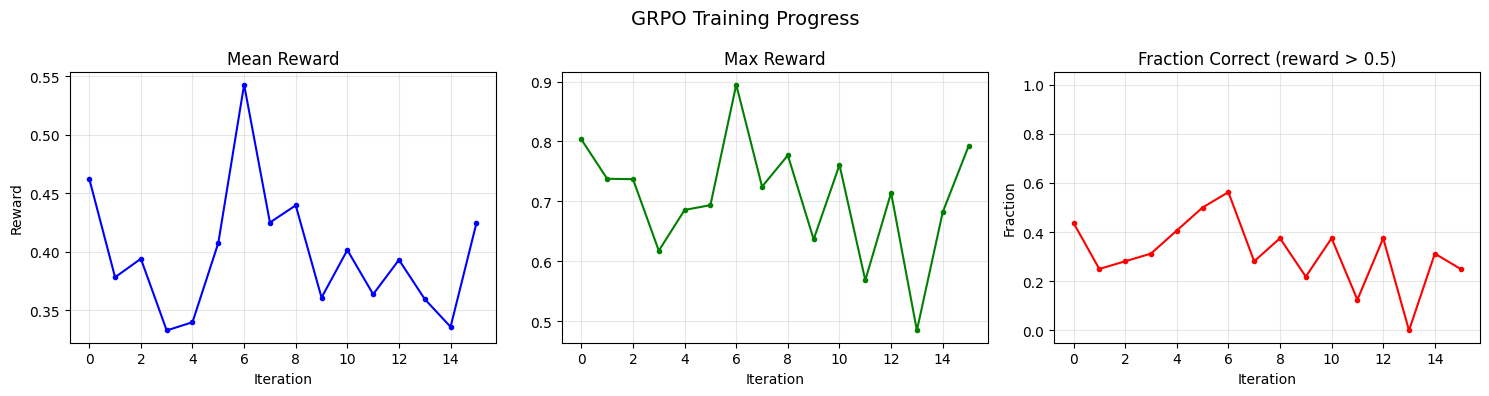

In [55]:
from matplotlib import pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

iters = [m['iteration'] for m in grpo_metrics]

axes[0].plot(iters, [m['mean_reward'] for m in grpo_metrics], 'b-o', markersize=3)
axes[0].set_title('Mean Reward')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Reward')
axes[0].grid(True, alpha=0.3)

axes[1].plot(iters, [m['max_reward'] for m in grpo_metrics], 'g-o', markersize=3)
axes[1].set_title('Max Reward')
axes[1].set_xlabel('Iteration')
axes[1].grid(True, alpha=0.3)

axes[2].plot(iters, [m['correct_frac'] for m in grpo_metrics], 'r-o', markersize=3)
axes[2].set_title('Fraction Correct (reward > 0.5)')
axes[2].set_xlabel('Iteration')
axes[2].set_ylabel('Fraction')
axes[2].set_ylim([-0.05, 1.05])
axes[2].grid(True, alpha=0.3)

plt.suptitle('GRPO Training Progress', fontsize=14)
plt.tight_layout()
plt.show()

## 9. Evaluate the Final Model

In [32]:
sft_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
sft_training_client.load_state("tinker://74e5f0bc-93c9-5df1-9570-5ed0910d9daa:train:0/weights/sft-final")
sft_sampling_client = sft_training_client.save_weights_and_get_sampling_client(name="sft-sampler.weekend")
grpo_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
grpo_training_client.load_state("tinker://eb393fba-89e6-5005-b2f2-3df09d6142c3:train:0/weights/grpo-final.weekend")
grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(name="grpo-sampler.weekend")

Comparing SFT vs GRPO model predictions + HOMO/LUMO constraint checks:

Prompt: Given the intermediate molecule SMILES <SMILES>CCCN1C(=O)[C@@]2(C(C(=O)OC)=C(N)OC3=C2C(=O)CCC3)c2ccccc21</SMILES>, which...
  Ground Truth: Replace C(=O)C1=C(N)OC2=C(C(=O)CCC2)[C@]12C(=O)N(CCC)c1ccccc12 with c1ccc2c(c1)[C@@](O)(C1(C#N)CCCCCC1)CC2 to form <SMILES>COc1ccc2c(c1)[C@@](O)(C1(C#N)CCCCCC1)CC2</SMILES>.
  SFT answer:   CCCN1C(=O)[C@@]2(C(C(=O)OC)=C(N)OC3=C2C(=O)CCC3)c2ccccc21
  GRPO answer:  None
  --- Constraint Check (proxy HOMO/LUMO deltas) ---
  Targets: HOMO None | LUMO None
  SFT:  ΔHOMO=0.0, score=0.24510033985756904, ok=False | ΔLUMO=0.0, score=0.23077527587727678, ok=False | overall_ok=False
  GRPO: ΔHOMO=None, score=None, ok=None | ΔLUMO=None, score=None, ok=None | overall_ok=False


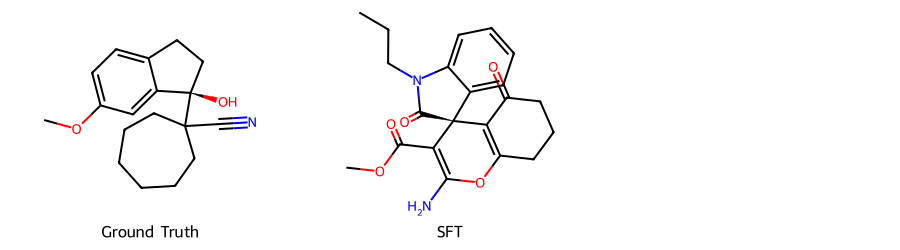


Prompt: Given the intermediate molecule SMILES <SMILES>Cc1cccc2c(=O)n(C/C([O-])=N/c3ncn[nH]3)cnc12</SMILES>, which is composed o...
  Ground Truth: Replace n1cnc2c(C)cccc2c1=O with n1cnc2ccccc2c1=O to form <SMILES>O=c1c2ccccc2ncn1C/C([O-])=N/c1ncn[nH]1</SMILES>.
  SFT answer:   C/C([O-])=N/c1ncn[nH]1c1cc2c([C@H]3C[C@H]3C(=O)N)ncn2c1
  GRPO answer:  C/C([O-])=N/c1ncn[nH]1c1ccccc1
  --- Constraint Check (proxy HOMO/LUMO deltas) ---
  Targets: HOMO None | LUMO None
  SFT:  ΔHOMO=None, score=None, ok=None | ΔLUMO=None, score=None, ok=None | overall_ok=False
  GRPO: ΔHOMO=None, score=None, ok=None | ΔLUMO=None, score=None, ok=None | overall_ok=False


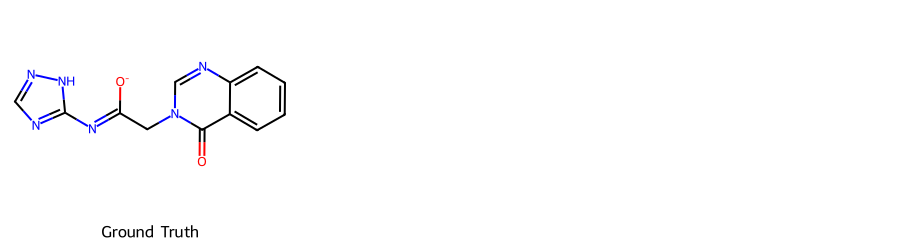


Prompt: Given the intermediate molecule SMILES <SMILES>C[C@H]([NH3+])[C@@H](CC(=O)[O-])c1ccccc1</SMILES>, which is composed of f...
  Ground Truth: Replace [C@H](CC(=O)[O-])[C@H](C)[NH3+] with n1[nH]c(=O)c2ccccc21 to form <SMILES>O=c1[nH]n(-c2ccccc2)c2ccccc12</SMILES>.
  SFT answer:   C[C@H]1C[C@H]2c3c([C@H]4[C@H](C)C[C@H]([NH3+])C[C@H]4C)CC[C@H]2c2c1C[C@H]([NH3+])C[C@H]2C
  GRPO answer:  C[C@H]1C[C@H](C)C[C@@H](C(=O)N2CC[C@H](C)C[C@H]2C)c2ccccc12
  --- Constraint Check (proxy HOMO/LUMO deltas) ---
  Targets: HOMO -1.241 | LUMO -0.734
  SFT:  ΔHOMO=None, score=None, ok=None | ΔLUMO=None, score=None, ok=None | overall_ok=False
  GRPO: ΔHOMO=1.909763030303031, score=0.02149247417812866, ok=False | ΔLUMO=-0.7803900000000004, score=0.9214409553074194, ok=True | overall_ok=False


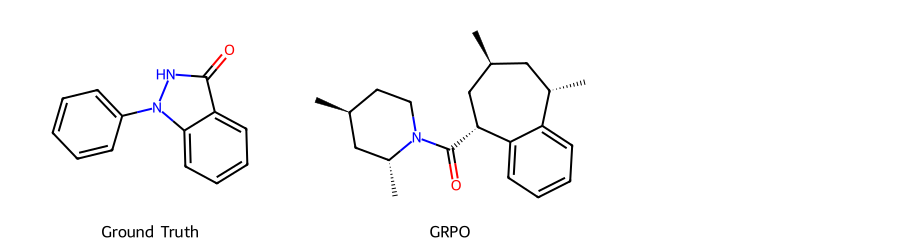


Prompt: Given the intermediate molecule SMILES <SMILES>COc1cccc(/N=C2\C(=O)N(C)c3ccccc32)c1</SMILES>, which is composed of fragm...
  Ground Truth: Replace c1cccc(/N=C2\C(=O)N(C)c3ccccc32)c1 with c1ccc2c(c1)[nH]c1c(=O)n(/N=C/c3ccc([N+](=O)[O-])cc3)c([O-])nc12 to form <SMILES>COc1ccc2c(c1)[nH]c1c(=O)n(/N=C/c3ccc([N+](=O)[O-])cc3)c([O-])nc12</SMILES>.
  SFT answer:   COc1ccc2c(c1)C(=O)N(C)c1ccccc12
  GRPO answer:  COc1ccc2c(c1)C(=O)N(C)c1ccccc12
  --- Constraint Check (proxy HOMO/LUMO deltas) ---
  Targets: HOMO -3.967 | LUMO -2.649
  SFT:  ΔHOMO=-0.15691666666666682, score=0.1746549206430597, ok=False | ΔLUMO=-0.06495299999999993, score=0.18359688066303995, ok=False | overall_ok=False
  GRPO: ΔHOMO=-0.15691666666666682, score=0.1746549206430597, ok=False | ΔLUMO=-0.06495299999999993, score=0.18359688066303995, ok=False | overall_ok=False


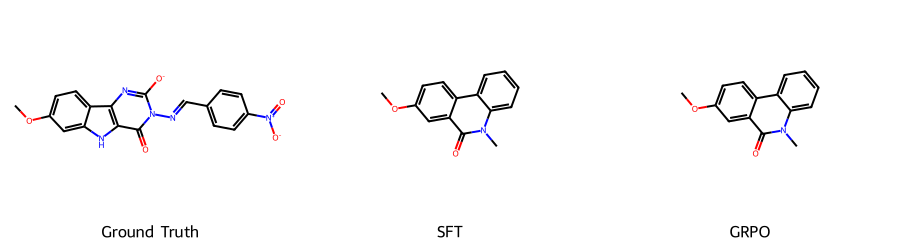


Prompt: Given the intermediate molecule SMILES <SMILES>Cc1cccc(-c2c3c(=O)n(C)c(=O)n(C)c3cn2N2CCOCC2)c1</SMILES>, which is compos...
  Ground Truth: Replace c1c2c(=O)n(C)c(=O)n(C)c2cn1N1CCOCC1 with n1ncc2c(N)ncnc21 to form <SMILES>Cc1cccc(-n2ncc3c(N)ncnc32)c1</SMILES>.
  SFT answer:   Cc1cccc(-c2c3c(=O)n(C)c(=O)n(C)c3cn2C)c1
  GRPO answer:  Cc1cccc(-c2c3c(=O)n(C)c(=O)n(C)c3cn2C)c1
  --- Constraint Check (proxy HOMO/LUMO deltas) ---
  Targets: HOMO 2.615 | LUMO 0.184
  SFT:  ΔHOMO=-0.30561210526315774, score=0.14407982430733687, ok=False | ΔLUMO=-0.20696100000000006, score=0.26213188237608886, ok=False | overall_ok=False
  GRPO: ΔHOMO=-0.30561210526315774, score=0.14407982430733687, ok=False | ΔLUMO=-0.20696100000000006, score=0.26213188237608886, ok=False | overall_ok=False


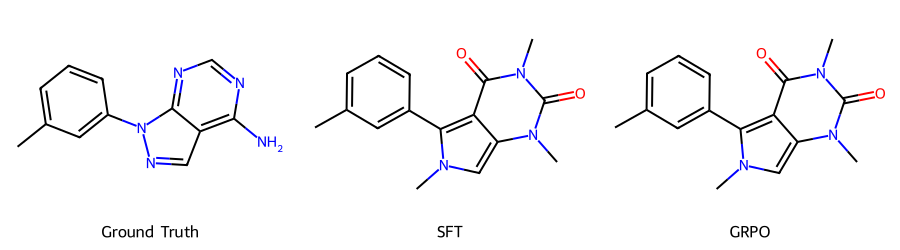


Summary (proxy-based checks)
SFT valid SMILES rate:  60.0%
GRPO valid SMILES rate: 60.0%
SFT constraint pass rate:  0.0%
GRPO constraint pass rate: 0.0%


In [57]:
# Compare SFT vs GRPO on a few test examples
from rdkit.Chem import Draw
from IPython.display import display

def evaluate_prompt_constraints(prompt_text, pred_smiles, score_threshold=0.65):
    """
    用当前reward同源的proxy方法，检查分子是否满足prompt中的HOMO/LUMO方向与幅度要求。
    返回详细指标，便于调试。
    """
    result = {
        "ok": False,
        "pred_valid": False,
        "homo_target": None,
        "lumo_target": None,
        "homo_delta": None,
        "lumo_delta": None,
        "homo_score": None,
        "lumo_score": None,
        "homo_ok": None,
        "lumo_ok": None,
    }

    if not pred_smiles:
        return result

    mol_pred = Chem.MolFromSmiles(pred_smiles)
    if mol_pred is None:
        return result
    result["pred_valid"] = True

    # 从prompt中解析目标改变量（higher/lower + 数值）
    homo_target = _extract_signed_delta(prompt_text, "HOMO")
    lumo_target = _extract_signed_delta(prompt_text, "LUMO")
    result["homo_target"] = homo_target
    result["lumo_target"] = lumo_target

    # 用prompt中的初始分子作为base，比较生成分子的改变量
    base_smiles = extract_smiles(prompt_text)
    mol_base = Chem.MolFromSmiles(base_smiles) if base_smiles else None

    homo_pred, lumo_pred = _predict_homo_lumo_proxy(mol_pred)
    homo_base, lumo_base = _predict_homo_lumo_proxy(mol_base)

    homo_delta = (homo_pred - homo_base) if (homo_pred is not None and homo_base is not None) else None
    lumo_delta = (lumo_pred - lumo_base) if (lumo_pred is not None and lumo_base is not None) else None
    result["homo_delta"] = homo_delta
    result["lumo_delta"] = lumo_delta

    # 和目标改变量匹配打分
    homo_score = _property_match_score(homo_delta, homo_target)
    lumo_score = _property_match_score(lumo_delta, lumo_target)
    result["homo_score"] = homo_score
    result["lumo_score"] = lumo_score

    homo_ok = (homo_score is not None) and (homo_score >= score_threshold)
    lumo_ok = (lumo_score is not None) and (lumo_score >= score_threshold)
    result["homo_ok"] = homo_ok if homo_score is not None else None
    result["lumo_ok"] = lumo_ok if lumo_score is not None else None

    # 至少一个可评估属性达标；若两个都可评估则要求都达标
    valid_flags = [x for x in [result["homo_ok"], result["lumo_ok"] if result["lumo_ok"] is not None else None] if x is not None]
    if len(valid_flags) == 0:
        result["ok"] = False
    elif len(valid_flags) == 1:
        result["ok"] = valid_flags[0]
    else:
        result["ok"] = all(valid_flags)

    return result

NUM_EVAL_EXAMPLES = 5
eval_indices = rng.choice(len(raw_data), size=NUM_EVAL_EXAMPLES, replace=False)

print("Comparing SFT vs GRPO model predictions + HOMO/LUMO constraint checks:\n")

sft_ok_list = []
grpo_ok_list = []
sft_valid_list = []
grpo_valid_list = []

for idx in eval_indices:
    example = raw_data[int(idx)]
    prompt_text = str(example[PROMPT_COL])
    ground_truth = str(example[ANSWER_COL])
    prompt_msgs = make_prompt_messages(example)
    prompt_input = renderer.build_generation_prompt(prompt_msgs)

    # Sample from SFT model
    sft_result = sft_sampling_client.sample(
        prompt=prompt_input,
        sampling_params=types.SamplingParams(
            max_tokens=GRPO_MAX_TOKENS, temperature=0.0, stop=stop_seqs
        ),
        num_samples=1,
    ).result()
    sft_text = tokenizer.decode(sft_result.sequences[0].tokens)
    sft_answer = extract_smiles(sft_text)

    # Sample from GRPO model
    grpo_result = grpo_sampling_client.sample(
        prompt=prompt_input,
        sampling_params=types.SamplingParams(
            max_tokens=GRPO_MAX_TOKENS, temperature=0.0, stop=stop_seqs
        ),
        num_samples=1,
    ).result()
    grpo_text = tokenizer.decode(grpo_result.sequences[0].tokens)
    grpo_answer = extract_smiles(grpo_text)

    # 约束检查
    sft_eval = evaluate_prompt_constraints(prompt_text, sft_answer)
    grpo_eval = evaluate_prompt_constraints(prompt_text, grpo_answer)

    sft_valid_list.append(sft_eval["pred_valid"])
    grpo_valid_list.append(grpo_eval["pred_valid"])
    sft_ok_list.append(sft_eval["ok"])
    grpo_ok_list.append(grpo_eval["ok"])

    gt_smiles = extract_smiles(ground_truth) or ground_truth.strip()
    gt_mol = Chem.MolFromSmiles(gt_smiles)
    sft_mol = Chem.MolFromSmiles(sft_answer) if sft_answer else None
    grpo_mol = Chem.MolFromSmiles(grpo_answer) if grpo_answer else None

    print(f"Prompt: {prompt_text[:120]}...")
    print(f"  Ground Truth: {ground_truth}")
    print(f"  SFT answer:   {sft_answer}")
    print(f"  GRPO answer:  {grpo_answer}")

    # 打印目标与预测改变量（proxy）
    print("  --- Constraint Check (proxy HOMO/LUMO deltas) ---")
    print(
        f"  Targets: HOMO {grpo_eval['homo_target']} | LUMO {grpo_eval['lumo_target']}"
    )
    print(
        f"  SFT:  ΔHOMO={sft_eval['homo_delta']}, score={sft_eval['homo_score']}, ok={sft_eval['homo_ok']} | "
        f"ΔLUMO={sft_eval['lumo_delta']}, score={sft_eval['lumo_score']}, ok={sft_eval['lumo_ok']} | overall_ok={sft_eval['ok']}"
    )
    print(
        f"  GRPO: ΔHOMO={grpo_eval['homo_delta']}, score={grpo_eval['homo_score']}, ok={grpo_eval['homo_ok']} | "
        f"ΔLUMO={grpo_eval['lumo_delta']}, score={grpo_eval['lumo_score']}, ok={grpo_eval['lumo_ok']} | overall_ok={grpo_eval['ok']}"
    )

    mols = []
    legends = []
    if gt_mol is not None:
        mols.append(gt_mol)
        legends.append("Ground Truth")
    if sft_mol is not None:
        mols.append(sft_mol)
        legends.append("SFT")
    if grpo_mol is not None:
        mols.append(grpo_mol)
        legends.append("GRPO")

    if mols:
        img = Draw.MolsToGridImage(mols, legends=legends, molsPerRow=3, subImgSize=(300, 250))
        display(img)
    else:
        print("  No valid molecules to render for this example.")

    print()

print("=" * 80)
print("Summary (proxy-based checks)")
print(f"SFT valid SMILES rate:  {np.mean(sft_valid_list):.1%}")
print(f"GRPO valid SMILES rate: {np.mean(grpo_valid_list):.1%}")
print(f"SFT constraint pass rate:  {np.mean(sft_ok_list):.1%}")
print(f"GRPO constraint pass rate: {np.mean(grpo_ok_list):.1%}")
print("=" * 80)

## 10. Download the Trained Weights

You can download the LoRA adapter weights to use with your own inference setup (e.g., vLLM, SGLang, or HuggingFace).

In [ ]:
# Download the GRPO model weights
# The downloaded weights are a LoRA adapter that can be loaded
# with HuggingFace PEFT or merged into the base model.

rest_client = service_client.create_rest_client()

# List available checkpoints
# rest_client.list_checkpoints()  # Uncomment to see all checkpoints

# Download to a local directory
# Uncomment and run when ready:
# rest_client.download_checkpoint(grpo_checkpoint_path, output_dir="./grpo-weights")
# print("Weights downloaded to ./grpo-weights/")

print(f"GRPO checkpoint path: {grpo_checkpoint_path}")
print("Uncomment the download line above when you're ready to export.")

---

## Summary & Next Steps

In this notebook, we:

1. **Loaded** the `Alan123/homo-lumo-grpo` dataset from HuggingFace
2. **SFT-trained** a Qwen3 model to learn the chemistry Q&A format using `cross_entropy` loss
3. **GRPO-trained** the model using RL with a custom reward function and `ppo` loss
4. **Compared** SFT vs GRPO predictions side by side

### Tips for better results:

- **More SFT steps** — if your dataset is large, train for more steps or multiple epochs
- **Tune the reward function** — the reward function is the most important part of GRPO. Make it reflect what you actually care about.
- **Try different loss functions** — Tinker supports `importance_sampling`, `ppo`, `cispo`, and `dro`. See the [Loss Functions docs](https://tinker-docs.thinkingmachines.ai/losses)
- **Increase samples per prompt** — more completions per prompt = better advantage estimates
- **Use a larger model** — `Qwen/Qwen3-30B-A3B` (MoE) is very cost-effective and much more capable
- **Use the Tinker Cookbook** — the cookbook has optimized training loops with async operations, logging, and eval. See [rl/train.py](https://github.com/thinking-machines-lab/tinker-cookbook/blob/main/tinker_cookbook/rl/train.py)

### Key Tinker resources:
- [Tinker API Docs](https://tinker-docs.thinkingmachines.ai/)
- [Supervised Learning Guide](https://tinker-docs.thinkingmachines.ai/supervised-learning/sl-basic)
- [RL Training Guide](https://tinker-docs.thinkingmachines.ai/rl/rl-basic)
- [Model Lineup](https://tinker-docs.thinkingmachines.ai/model-lineup)
- [Tinker Cookbook (GitHub)](https://github.com/thinking-machines-lab/tinker-cookbook)